#  TASKS
# 1. Load the CSV. Display shape, data types, descriptive statistics, missing values, and the first five rows.

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold,cross_validate, cross_val_score, GridSearchCV
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

df = pd.read_csv("Documents/lab_ticket_resolution (2).csv") 
print(df.shape) 
print(df.dtypes) 
print(df.describe(include="all")) 
print(df.isna().sum())

(240, 6)
ticket_id                    str
complexity_score           int64
lines_changed              int64
team_experience_years    float64
reopened                   int64
resolution_hours         float64
dtype: object
       ticket_id  complexity_score  lines_changed  team_experience_years  \
count        240        240.000000     240.000000             240.000000   
unique       240               NaN            NaN                    NaN   
top        T0001               NaN            NaN                    NaN   
freq           1               NaN            NaN                    NaN   
mean         NaN          5.491667      54.820833               6.105417   
std          NaN          2.979697      26.145017               3.391426   
min          NaN          1.000000       1.000000               0.500000   
25%          NaN          3.000000      33.000000               3.300000   
50%          NaN          5.500000      54.000000               5.800000   
75%          NaN   

# 2. Define `resolution_hours` as y. Exclude `ticket_id` from X. Write down which features are available at the intended prediction time and justify exclusions.

In [7]:
y = df["resolution_hours"]  # what the model is gonna predict

X = df[
    [
        "complexity_score",
        "team_experience_years"
    ]
] # what we give for the model

print("Feature shape:", X.shape)
print("Target shape:", y.shape)


Feature shape: (240, 2)
Target shape: (240,)



what we take as x is what we give the model as an input and also it should be usefull and known for the model to give the final prediction.
what we use as y is the final output we expect from the model as a result of the prediction.
y: resolution hours because that is what the model is gonn apredict
x: complexity score and team experiance years as they both useful to predict how much time it takes to finish the task
what are  excluded
1.ticket id: it is arbitrarily assigned value which isn't useful in the process of prediction
2.lines changed: it is known at the end so it isn't readily available  at the time of prediction
3.re opened : this is also decided after the task is finished

# 3. Split data into training and test sets (suggested 80/20, random_state=42). Do not use the test set to choose
model settings.

In [8]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (192, 2)
X_test: (48, 2)
y_train: (192,)
y_test: (48,)


We split the dataset into training and test sets so that the model can learn from one set of data and be evaluated on the rest not seen data.

In [10]:
kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

K-fold divides the training data into five folds. It trains the model five times. In each round, four folds are used to train the model and the remaining fold is used to validate it. 

# 4. Fit a `DummyRegressor(strategy='mean')` baseline and record its test metrics.
# 5. Fit `LinearRegression` on the selected features. Record MAE, RMSE, and R2.
# 6. Create a pipeline with `PolynomialFeatures` and `StandardScaler` followed by linear regression. Compare degrees 2 and 3 using cross-validation on the training set.

In [14]:
# model comparison

models = {
    "Dummy": DummyRegressor(strategy="mean"),

    "Degree 1": LinearRegression(),

    "Degree 2": make_pipeline(
        PolynomialFeatures(degree=2, include_bias=False),
        StandardScaler(),
        LinearRegression()
    ),

    "Degree 3": make_pipeline(
        PolynomialFeatures(degree=3, include_bias=False),
        StandardScaler(),
        LinearRegression()
    )
}

results = []

for name, model in models.items():

    
    model.fit(X_train, y_train) #training

    # Evaluation
    train_pred = model.predict(X_train)
    train_mae = mean_absolute_error(y_train, train_pred)
    train_rmse = mean_squared_error(y_train, train_pred) ** 0.5
    train_r2 = r2_score(y_train, train_pred)

    
    test_pred = model.predict(X_test)
    test_mae = mean_absolute_error(y_test, test_pred)
    test_rmse = mean_squared_error(y_test, test_pred) ** 0.5
    test_r2 = r2_score(y_test, test_pred)

    # cross validation
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=kf,
        scoring={
            "mae": "neg_mean_absolute_error",
            "rmse": "neg_root_mean_squared_error",
            "r2": "r2"
        }
    )

    results.append({
    "Model": name,
    "Train MAE": train_mae,
    "Test MAE": test_mae,
    "CV MAE": -scores["test_mae"].mean(),

    "Train RMSE": train_rmse,
    "Test RMSE": test_rmse,
    "CV RMSE": -scores["test_rmse"].mean(),

    "Train R²": train_r2,
    "Test R²": test_r2,
    "CV R²": scores["test_r2"].mean()
})

results_df = pd.DataFrame(results)

print(results_df.round(3).to_string(index=False))




   Model  Train MAE  Test MAE  CV MAE  Train RMSE  Test RMSE  CV RMSE  Train R²  Test R²  CV R²
   Dummy      8.418     9.114   8.448       9.869     10.598    9.884     0.000   -0.021 -0.023
Degree 1      3.127     2.906   3.168       3.869      3.572    3.909     0.846    0.884  0.838
Degree 2      3.063     3.020   3.131       3.770      3.741    3.832     0.854    0.873  0.844
Degree 3      3.007     3.140   3.162       3.702      3.949    3.877     0.859    0.858  0.841


**MAE  (Mean Absolute Error)**
MAE tells us how far the model's predictions are from the actual values on average, ignoring whether the prediction was too high or too low.

**RMSE (Root Mean Squared Error)**
RMSE also measures prediction error in hours, but it penalizes large errors more heavily than MAE does.

**R² (Coefficient of Determination)**
R² measures how well the model predicts compared with a baseline that predicts the mean target value. It is commonly described as the proportion of variation in the target explained by the model, with some important qualifications.

Dummy baseline performed poorly because it predicts the same average resolution time for every ticket without considering its complexity or the team's experience. Degree 1 performed well this suggests that much of the data relation can be described by relatively simple linear relationships but that doesn't mean all relations are linear.
Degree 2 can learn curved relationships in the data. It performed slightly better than degree 3 during cross-validation and showed similar training and test performance, suggesting it can predict new data reliably. Degree 3 can learn more complex patterns, but it performed slightly worse than degree 2. It did better on training data but worse on test data, suggesting that it may be overfitting.

# 7. Fit Ridge and Lasso models using a pipeline that scales features. Select alpha with cross-validation or a small validation grid. Record the selected value and results.

In [17]:
alpha_values = [1e-10, 1e-9, 1e-8, 1e-7, 1e-6, 1e-5]

# Ridge Regression
ridge_pipeline = make_pipeline(
    StandardScaler(),
    Ridge()
)

ridge_grid = GridSearchCV(
    ridge_pipeline,
    {"ridge__alpha": alpha_values},
    cv=kf,
    scoring="neg_mean_absolute_error"
)

ridge_grid.fit(X_train, y_train)

# Lasso Regression
lasso_pipeline = make_pipeline(
    StandardScaler(),
    Lasso(max_iter=10000)
)

lasso_grid = GridSearchCV(
    lasso_pipeline,
    {"lasso__alpha": alpha_values},
    cv=kf,
    scoring="neg_mean_absolute_error"
)

lasso_grid.fit(X_train, y_train)

# Compare
for name, grid in [
    ("Ridge", ridge_grid),
    ("Lasso", lasso_grid)
]:
    model = grid.best_estimator_
    predictions = model.predict(X_test)

    print(f"\n{name} Regression")
    print("Best alpha:", grid.best_params_[f"{name.lower()}__alpha"])
    print("CV MAE:", round(-grid.best_score_, 3))
    print("Test MAE:", round(mean_absolute_error(y_test, predictions), 3))
    print("Test RMSE:", round(np.sqrt(mean_squared_error(y_test, predictions)), 3))
    print("Test R²:", round(r2_score(y_test, predictions), 3))


Ridge Regression
Best alpha: 1e-10
CV MAE: 3.168
Test MAE: 2.906
Test RMSE: 3.572
Test R²: 0.884

Lasso Regression
Best alpha: 1e-10
CV MAE: 3.168
Test MAE: 2.906
Test RMSE: 3.572
Test R²: 0.884


Ridge and Lasso performed almost exactly like regular Linear Regression. Both chose a very small alpha, meaning they needed very little adjustment to the model. This suggests that regularization did not improve the results much for this dataset.

# 8. Plot observed versus predicted values and a residual plot for at least two models. Look for curvature, changing spread, and influential outliers.

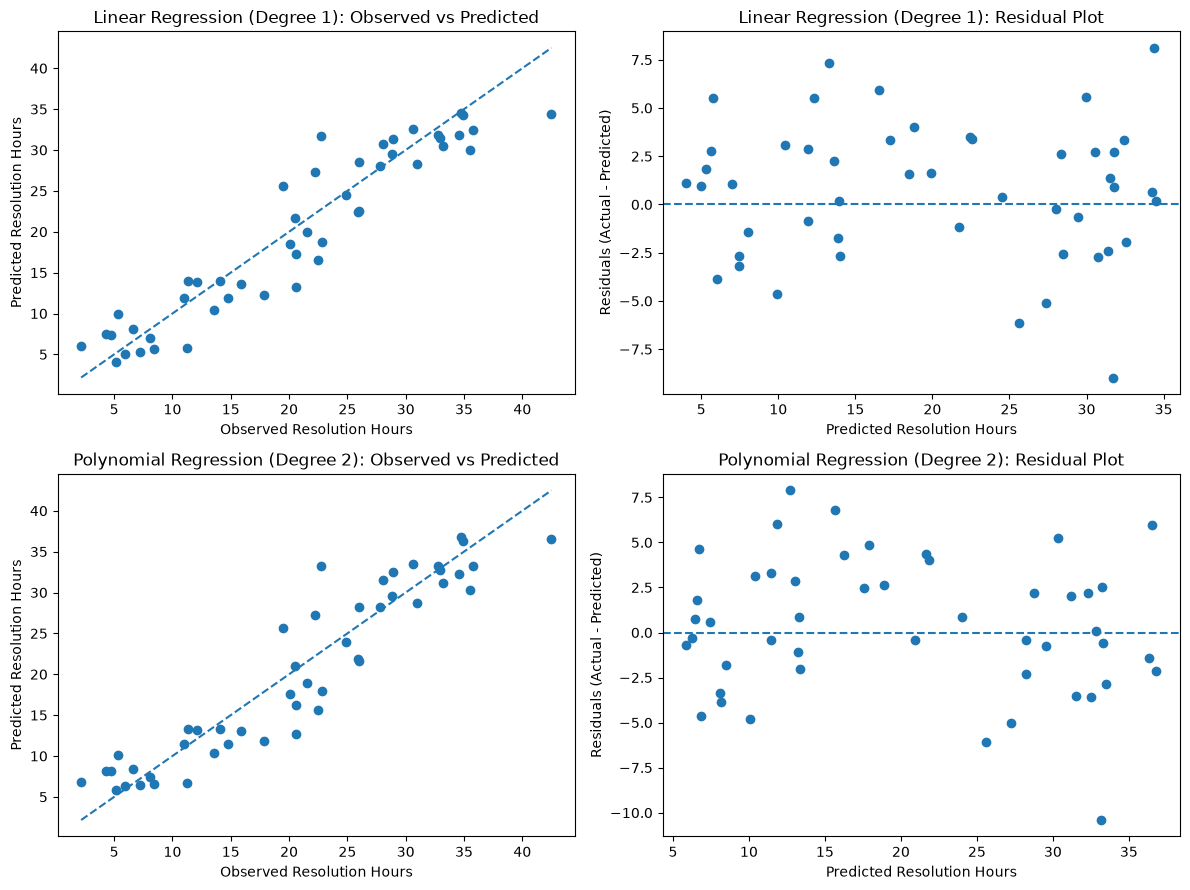

In [18]:
models = {
    "Linear Regression (Degree 1)": make_pipeline(
        StandardScaler(),
        LinearRegression()
    ),
    "Polynomial Regression (Degree 2)": make_pipeline(
        PolynomialFeatures(degree=2, include_bias=False),
        StandardScaler(),
        LinearRegression()
    )
}

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for i, (name, model) in enumerate(models.items()):
    model.fit(X_train, y_train)     # Train it and predict test values
    y_pred = model.predict(X_test)

    residuals = y_test - y_pred  # Resuduals

    # Observed vs predicted plot
    axes[i, 0].scatter(y_test, y_pred)
    axes[i, 0].plot(
        [y_test.min(), y_test.max()],
        [y_test.min(), y_test.max()],
        linestyle="--"
    )
    axes[i, 0].set_title(f"{name}: Observed vs Predicted")
    axes[i, 0].set_xlabel("Observed Resolution Hours")
    axes[i, 0].set_ylabel("Predicted Resolution Hours")

    # Residual plt
    axes[i, 1].scatter(y_pred, residuals)
    axes[i, 1].axhline(y=0, linestyle="--")
    axes[i, 1].set_title(f"{name}: Residual Plot")
    axes[i, 1].set_xlabel("Predicted Resolution Hours")
    axes[i, 1].set_ylabel("Residuals (Actual - Predicted)")

plt.tight_layout()
plt.show()

**Linear Regression (degree 1)**: Most predictions are close to the actual values. The errors are scattered around zero, but a few predictions are quite far off. There is no clear curved pattern.
**Polynomial Regression (degree 2)**: Its predictions are also close to the actual values, with a similar error pattern. However, it still has a few large errors, and there is no clear sign that it performs much better than degree 1.

# 9. Write a short recommendation: which model would you choose for this dataset, what evidence supports it,
and what further data or checks would be needed?

I would choose Linear Regression (degree 1) because it is simpler and gave slightly better test results. Both models performed well, but degree 2 did not offer enough improvement to justify the extra complexity. I would check the large prediction errors and test the model on more data to see if it stays reliable.

# Analysis questions
10. Why is the mean baseline useful even though it ignores all features?
     -The mean baseline gives us a simple starting point by predicting the average resolution time for every ticket. It helps us see whether our models can make better predictions than simply using the average.
    
11. Which model has the lowest MAE? Which has the lowest RMSE? Are they the same, and why might they
differ?
     -Linear Regression (degree 1) had the lowest MAE and RMSE on the test data. Both measure how far predictions are from actual times, but RMSE gives more importance to bigger mistakes. They can sometimes favor different models because some models make larger mistakes than others.

12. Did polynomial features improve validation performance? What is the evidence of possible overfitting?
     -Degree 2 performed slightly better than degree 1 during cross-validation, but degree 3 did not improve the results. Degree 3 did better on training data but worse on test data, suggesting it may have learned the training data too closely and struggled more with new tickets.
    
13. How did regularization affect performance and coefficient magnitudes?
     -Ridge and Lasso gave almost the same results as regular Linear Regression. They chose a very small alpha, so they made very little change to the model. As a result, regularization did not noticeably improve performance.
    
14. Why is scaling included in the Ridge/Lasso pipeline?
     -Scaling puts the features on a similar scale, even if they originally use different ranges. This helps Ridge and Lasso adjust the model fairly.
    
15. Identify one potential leakage issue in the dataset and explain how you handled it.
     -The lines_changed and reopened features might only be known after work on a ticket has started. Using them could give the model information it would not have when the ticket is first created. I excluded them and used ticket complexity and team experience instead.

16. Would a random split be appropriate if tickets were collected over several years or came from repeated
customers/teams? Explain.
     -Not always. A random split might put tickets from the same team or customer in both training and test data, making the model seem more accurate than it really is. For tickets collected over several years, I would train using older tickets and test using newer ones.

17. What additional tests would you perform before deploying this model?
     -I would test the model on newer tickets, check the tickets where its predictions were far from the actual times, and see whether it works well for different teams and ticket types. This would help me decide whether it is reliable enough to use in real situations.



# EBISE TEKLE
# UGR/9482/16